# EDA de WDSD: segmentación de tornillos en residuos electrónicos

**Autores:** Jose David Castillo e Ivan Berrio.

**Proyecto final de Deep Learning, entregable 1. Secciones 1 y 2 del enunciado.**

**Conclusión:** WDSD es válido para el proyecto y se recomienda continuar con él. Es un problema de **segmentación de imágenes** (tipo 8 del enunciado), público y con 945 pares imagen-máscara íntegros.

Tres hallazgos condicionan todo lo que sigue:

1. **La partición oficial tiene fuga.** El 48,9 % de las imágenes de test tiene una casi-gemela en train, y 31 de los 40 grupos por nombre cruzan particiones. Aquí se propone una partición agrupada de 744 / 93 / 108 imágenes, sin grupos compartidos.
2. **Los objetos son diminutos.** El tornillo ocupa el 0,09 % de los píxeles (1.084:1) y su diámetro mediano es de 11,5 px. Predecir todo fondo da 99,9 % de exactitud y Dice 0, así que la exactitud de píxel no sirve como métrica.
3. **Reducir la imagen sale caro.** Una máscara perfecta reescalada a 256×256 ya pierde Dice (0,84). Por eso se recomienda trabajar con parches de 512×512 a resolución nativa.

No se entrenó ningún modelo de segmentación. El bosque aleatorio de la sección 11 solo mide el desplazamiento entre particiones.


## 0. Configuración

El notebook se ejecuta de principio a fin con el entorno `ml_venv`. Las medidas costosas quedan en `results/eda/`. Las dos partes de la descarga deben estar extraídas como `WDSD-*-1-001` y `WDSD-*-1-002`, junto a la carpeta `wdsd-entregable-1`.


In [1]:
import sys, json, platform, warnings
from pathlib import Path
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, matplotlib.ticker
from PIL import Image
from scipy import stats
from skimage.segmentation import find_boundaries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from wdsd_e1 import eda as E

SEED = E.SEED
UMBRAL_PHASH = 60
np.random.seed(SEED)
COLOR = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}
TINTA, GRIS = '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ae',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': .7, 'axes.axisbelow': True,
    'text.color': TINTA, 'axes.labelcolor': GRIS, 'xtick.color': GRIS, 'ytick.color': GRIS,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9.5, 'legend.frameon': False})
pd.set_option('display.width', 180, 'display.max_columns', 30)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

Python 3.9.25 | numpy 1.25.2 | pandas 2.1.0 | matplotlib 3.7.2


## 1. Definición del problema y del dataset

### 1.1 Definición formal

Sea $\mathcal{X} = [0,255]^{720 \times 1280 \times 3}$ el espacio de imágenes RGB e $\mathcal{Y} = \{0,1\}^{720 \times 1280}$ el de máscaras binarias, donde 1 indica píxel de tornillo. Se busca $f_\theta : \mathcal{X} \to [0,1]^{720 \times 1280}$ que minimice sobre train una pérdida de solapamiento más una de píxel:

$$\mathcal{L}(\hat y, y) = \underbrace{1 - \frac{2\sum_i \hat y_i y_i + \epsilon}{\sum_i \hat y_i + \sum_i y_i + \epsilon}}_{\text{Dice}} + \lambda\, \mathcal{L}_{\text{BCE o focal}}(\hat y, y)$$

**Tipo de problema:** segmentación de imágenes, tipo 8 de los diez admitidos. Se sigue el bloque G del EDA y la guía 6.8.

**Pregunta de investigación:** ¿qué nivel de Dice alcanzan los modelos de segmentación más básicos de la literatura en tornillos de residuos electrónicos, evaluados en sesiones de adquisición no vistas?

**Hipótesis operativa:** al evaluar con una partición agrupada, al menos un modelo base difiere del resto en Dice por imagen en más de $\delta$.

### 1.2 Declaración a priori (propuesta)

| Elemento | Decisión |
|---|---|
| Métrica primaria | Dice de la clase tornillo, promediado por imagen |
| Secundarias | IoU de tornillo, mIoU, exactitud de píxel, precisión y recall por instancia |
| Margen $\delta$ | 0,02 de Dice, provisional hasta el piloto de la sección 4.1 |
| Significancia | $\alpha = 0{,}05$ |
| Unidad de análisis | La imagen, como pide el enunciado para segmentación |
| Unidad de independencia | El grupo de independencia, definido en la sección 4 |

Se eligió Dice porque, en la sección 6, la exactitud de píxel no distingue un modelo inútil de uno bueno. El valor $\delta = 0{,}02$ equivale a una quinta parte de lo que cuesta un error de borde de 1 px (0,104, sección 10): es lo bastante grande para no premiar ruido de contorno. Queda sujeto a la $\hat\sigma_d$ del piloto.

### 1.3 Justificación del dataset

- **Relevancia:** localizar tornillos es un paso previo al desensamblaje robotizado de residuos electrónicos (WEEE), una tarea repetitiva y con potencial de automatización.
- **Procedencia:** WEEE Disassembly Screw Dataset, publicado por el Visual Computing Lab del ITI/CERTH. Las imágenes vienen de laboratorio y de plantas de reciclaje, sobre torres de PC, microondas y pantallas.
- **Referencia:** Kalitsios, Lazaridis, Psaltis, Axenopoulos y Daras, *Vision-Enhanced System for Human-Robot Disassembly Factory Cells: Introducing A New Screw Dataset*, ICRCV 2022. Página: <https://vcl.iti.gr/dataset/weee-disassembly-screw-dataset/>
- **Etiquetado:** humano, con anotaciones en formato COCO para detección, instancias y semántica. La página indica que se usó una estimación de desenfoque para excluir fotogramas borrosos antes de anotar.

**Pendientes de verificar con la fuente:**

- La página **no declara licencia**, y el enunciado exige documentarla.
- La página no da DOI.
- Sus cifras de ambiente se contradicen: 52,7 % / 47,3 % en un punto y 58,7 % / 41,3 % en otro.
- Declara 4.414 instancias, y los JSON suman 4.398.

### 1.4 Descripción técnica

| Aspecto | Valor |
|---|---|
| Observaciones | 945 pares imagen-máscara |
| Formato | PNG, RGB de 8 bits, 1280×720; máscara en escala de grises con valores 0 y 255 |
| Clases | Una (`Screw`) más fondo |
| Unidad de observación | Fotograma |
| Dependencia | Agrupada: fotogramas de una misma sesión o escena |
| Trazabilidad | SHA-256 del dataset, impreso en la sección 2 |

El dataset no trae una etiqueta de dispositivo por imagen. Los nombres de archivo definen **familias de adquisición**, que aquí sirven como aproximación a sesión y ambiente, no como tipo de equipo.


## 2. Integridad y trazabilidad

Este paso comprueba que los archivos coincidan con la distribución oficial: 765 / 90 / 90. Solo se usan nombres, hashes y formatos, no el contenido de las imágenes.


In [2]:
df = E.inventario()
oficial = pd.Series({'train': 765, 'val': 90, 'test': 90})
coco = E.carga_coco()
tabla = pd.DataFrame({
    'imagenes': df.groupby('split_oficial').size(),
    'con_mascara': df.groupby('split_oficial').ruta_mask.apply(lambda s: s.notna().sum()),
    'con_visualizacion': df.groupby('split_oficial').ruta_vis.apply(lambda s: s.notna().sum()),
    'en_coco': pd.Series({k: len(v['images']) for k, v in coco.items()}),
    'instancias_coco': pd.Series({k: len(v['annotations']) for k, v in coco.items()}),
    'oficial': oficial}).loc[['train', 'val', 'test']]
tabla.loc['total'] = tabla.sum()
display(tabla)
print('Carpetas unidas:', [p.parent.name for p in E.data_roots()])
print('Imágenes sin máscara:', df.ruta_mask.isna().sum(), '| categorías COCO:', coco['train']['categories'])
print('SHA-256 del dataset:', E.huella_dataset(df))

,imagenes,con_mascara,con_visualizacion,en_coco,instancias_coco,oficial
train,765,765,765,765,3578,765
val,90,90,90,90,402,90
test,90,90,90,90,418,90
total,945,945,945,945,4398,945


Carpetas unidas: ['WDSD-20261106T223843Z-1-001', 'WDSD-20261106T223843Z-1-002']
Imágenes sin máscara: 0 | categorías COCO: [{'supercategory': 'none', 'id': 1, 'name': 'Screw'}]
SHA-256 del dataset: 39117b86f77b4f4277045d904848291306b4492bcd553872d6dddb097c4544a4


In [3]:
partes = pd.crosstab(df.familia, df.parte_img)
chi2, p, gl, _ = stats.chi2_contingency(partes[partes.sum(1) >= 5])
misma = (df.parte_img == df.parte_mask).mean()
print(f'Familia x parte de descarga: chi2={chi2:.2f}, gl={gl}, p={p:.3f}')
print(f'Imagen y máscara del mismo par en la misma parte: {misma:.1%}')
print(f'Pares completos que se tendrían solo con la parte 1: {(df.parte_img.eq(1) & df.parte_mask.eq(1)).sum()} de {len(df)}')

mi = E.medidas_imagen(df)
mm, ins = E.medidas_mascara(df)
print('\nFormato de imagen y máscara:')
display(mi[['ancho', 'alto', 'modo', 'ancho_m', 'alto_m', 'modo_m']].value_counts().rename('n').reset_index())
print('Valores en las máscaras:', mm.valores.value_counts().to_dict())
print('Máscaras vacías:', (mm.px_fg == 0).sum())
print('Hashes de imagen repetidos:', df.sha256_img.duplicated().sum(), '| de máscara:', df.sha256_mask.duplicated().sum())
print('Nombres repetidos entre particiones:', df.archivo.duplicated().sum())

Familia x parte de descarga: chi2=1.52, gl=7, p=0.982
Imagen y máscara del mismo par en la misma parte: 47.8%
Pares completos que se tendrían solo con la parte 1: 226 de 945

Formato de imagen y máscara:


,ancho,alto,modo,ancho_m,alto_m,modo_m,n
0,1280,720,RGB,1280,720,L,945


Valores en las máscaras: {'0,255': 945}
Máscaras vacías: 0
Hashes de imagen repetidos: 0 | de máscara: 0
Nombres repetidos entre particiones: 0


**Lectura.** Tras unir las dos descargas hay 945 imágenes, 945 máscaras y 945 visualizaciones, con coincidencia exacta con la distribución oficial. No hay faltantes, archivos corruptos, máscaras vacías, valores fuera de {0, 255} ni diferencias de resolución entre imagen y máscara.

**Mecanismo de los faltantes.** Con una sola descarga faltarían archivos, pero ese faltante es aleatorio y no depende del contenido. La familia es independiente de la parte (χ² = 1,52, gl = 7, p = 0,98), e imagen y máscara del mismo par caen en la misma parte el 47,8 % de las veces, cerca del azar. La parte 1 sola daría 226 pares. Es compatible con MCAR y se resuelve uniendo las partes.

Hay un segundo mecanismo que sí es selectivo. Los autores excluyeron fotogramas borrosos, y todas las imágenes contienen al menos un tornillo. Ese filtro depende de la observación, por lo que el dataset no representa el desenfoque ni las escenas sin tornillos.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Unir ambas partes. Binarizar las máscaras con `mask > 0`. Usar el PNG semántico como verdad de referencia. |
| **Arquitectura** | Salida de un canal con sigmoide. No hace falta manejar resoluciones variables. |
| **Riesgos** | Falsos positivos no medibles a nivel de imagen, porque no hay imágenes negativas. Sensibilidad no medida ante desenfoque. Licencia sin confirmar. |


## 3. Dependencia entre imágenes y duplicados

Son fotogramas de video, así que el riesgo principal es la **fuga por escena**: la misma escena en train y en test. Se mide con dos señales independientes de la etiqueta: el nombre del archivo y un hash perceptual DCT de 255 bits.


In [4]:
D = E.matriz_phash(df).copy()
np.fill_diagonal(D, 999)
sesiones = df.groupby('grupo_nombre').split_oficial.nunique()
print(f'Grupos por nombre: {len(sesiones)}; repartidos entre particiones oficiales: {(sesiones > 1).sum()}')
tab = pd.crosstab(df.grupo_nombre, df.split_oficial)[['train', 'val', 'test']]
print('Ejemplos:'); display(tab[(tab.val > 0) & (tab.test > 0)].sort_values('train', ascending=False).head(8).T)

filas = []
for a, b in [('val', 'train'), ('test', 'train'), ('test', 'val')]:
    x = D[np.ix_(df.split_oficial == a, df.split_oficial == b)].min(1)
    filas.append({'consulta': a, 'referencia': b, 'mediana_dist': np.median(x), 'pct_<=20': (x <= 20).mean() * 100,
                  'pct_<=40': (x <= 40).mean() * 100, f'pct_<={UMBRAL_PHASH}': (x <= UMBRAL_PHASH).mean() * 100})
fuga_oficial = pd.DataFrame(filas).round(1)
display(fuga_oficial)

Grupos por nombre: 40; repartidos entre particiones oficiales: 31
Ejemplos:


grupo_nombre,screws,frame,eco13,eco12,numerico,eco9,eco10,pc_17
split_oficial,,,,,,,,
train,164,125,43,25,23,20,15,14
val,13,26,2,2,3,2,3,1
test,25,7,3,1,4,4,2,1


,consulta,referencia,mediana_dist,pct_<=20,pct_<=40,pct_<=60
0,val,train,97.0,11.1,16.7,27.8
1,test,train,62.0,16.7,26.7,48.9
2,test,val,92.0,3.3,3.3,12.2


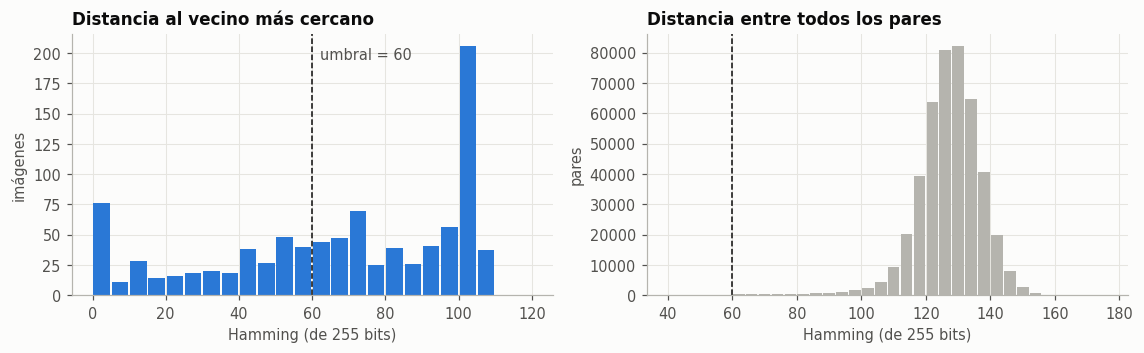

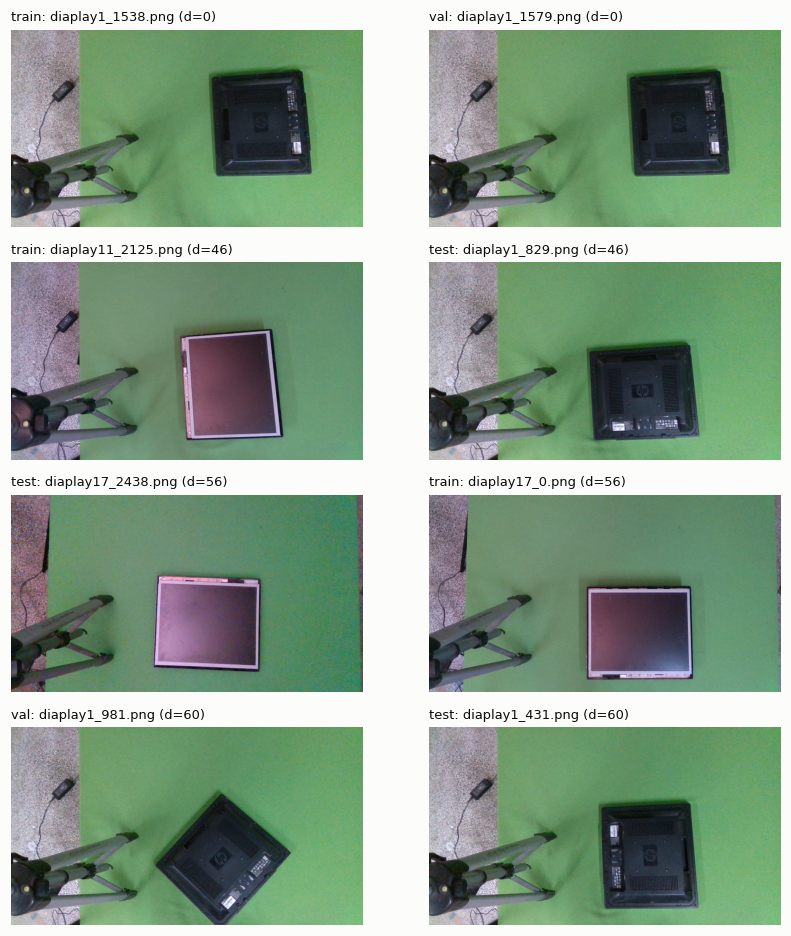

Pares entre particiones oficiales con d <= 60: 288
Mediana de la distancia entre todos los pares: 126 bits
screws: distancia mediana entre números consecutivos = 118 bits; al vecino más cercano de la familia = 64 bits
frame: distancia mediana entre números consecutivos = 126 bits; al vecino más cercano de la familia = 106 bits


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
vec = D.min(1)
axs[0].hist(vec, bins=np.arange(0, 125, 5), color=COLOR['train'], rwidth=.9)
axs[0].axvline(UMBRAL_PHASH, color=TINTA, lw=1, ls='--')
axs[0].annotate(f'umbral = {UMBRAL_PHASH}', (UMBRAL_PHASH + 2, axs[0].get_ylim()[1] * .9), color=GRIS)
axs[0].set(title='Distancia al vecino más cercano', xlabel='Hamming (de 255 bits)', ylabel='imágenes')
aleatorio = D[np.triu_indices_from(D, 1)]
axs[1].hist(aleatorio, bins=np.arange(40, 180, 4), color='#b5b4ae', rwidth=.9)
axs[1].axvline(UMBRAL_PHASH, color=TINTA, lw=1, ls='--')
axs[1].set(title='Distancia entre todos los pares', xlabel='Hamming (de 255 bits)', ylabel='pares')
plt.tight_layout(); plt.show()

sp = df.split_oficial.values
pares = [(D[i, j], i, j) for i in range(len(df)) for j in range(i + 1, len(df)) if sp[i] != sp[j] and D[i, j] <= UMBRAL_PHASH]
pares.sort()
elegidos = [pares[int(q * (len(pares) - 1))] for q in (0, .35, .7, 1)]
fig, axs = plt.subplots(len(elegidos), 2, figsize=(8, 8.6))
for f, (d, i, j) in enumerate(elegidos):
    for c, k in enumerate((i, j)):
        axs[f, c].imshow(Image.open(df.ruta_img[k]).resize((640, 360)))
        axs[f, c].set_title(f'{df.split_oficial[k]}: {df.archivo[k]} (d={d})', fontsize=8.5, fontweight='normal')
        axs[f, c].axis('off')
plt.tight_layout(); plt.show()
print(f'Pares entre particiones oficiales con d <= {UMBRAL_PHASH}: {len(pares)}')
print(f'Mediana de la distancia entre todos los pares: {np.median(aleatorio):.0f} bits')
for f in ('screws', 'frame'):
    o = df[df.grupo_nombre == f].sort_values('n_frame').index.to_numpy()
    print(f'{f}: distancia mediana entre números consecutivos = {np.median(D[o[:-1], o[1:]]):.0f} bits; al vecino más cercano de la familia = {np.median(D[np.ix_(o, o)].min(1)):.0f} bits')

**Lectura.** No hay duplicados exactos, pero sí muchos casi-duplicados. En la partición oficial, 31 de los 40 grupos por nombre cruzan particiones. El 48,9 % de test y el 27,8 % de val tienen una imagen en train a distancia ≤ 60, cuando la mediana entre todos los pares es de 126 bits. Hay 288 pares así entre particiones oficiales, y la figura muestra que corresponden a la misma escena, incluso en el extremo del umbral.

Las métricas sobre la partición oficial medirían en parte memoria de la escena, no capacidad de generalizar. El enunciado prohíbe expresamente esta fuga por agrupamiento.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Descartar la partición oficial como partición principal y reagrupar antes de cualquier análisis de contenido. |
| **Arquitectura** | Ninguna decisión directa, pero sin este paso la comparación entre modelos favorecería a los de mayor capacidad, que memorizan mejor. |
| **Riesgos** | Resultados inflados si se usa la partición oficial. Los trabajos que la usen podrían no ser comparables con este baseline. El pHash no detecta el mismo equipo físico en otra posición. |


## 4. Partición propuesta

**Regla de agrupación.** Dos imágenes pertenecen al mismo grupo si se cumple alguna de estas condiciones, y los grupos son las componentes conexas resultantes:

1. Comparten sesión en el nombre (`pc_8`, `eco13`, `micro_6`, `numerico`...).
2. Son de la familia `frame` y caen en el mismo bloque de 200 números. Esa familia es cámara en mano en planta y mezcla muchos equipos.
3. Su distancia pHash es ≤ 60.

La familia `screws` se agrupa solo por similitud, porque su numeración no es temporal: dos números consecutivos están a 118 bits en mediana, casi como pares aleatorios.

**Reparto.** Grupos completos, objetivo 80/10/10, semilla 42, equilibrando familias con búsqueda local. La asignación usa solo familia y tamaño de grupo, sin mirar la etiqueta.


,umbral,grupos,grupo_mayor,pct_en_top3
0,30,247,48,13.3
1,40,239,48,13.3
2,50,227,48,13.9
3,60,186,48,13.9
4,70,136,64,16.7


Grupos de independencia: 186 | en más de una partición: 0


split,train,val,test,pct_train
familia,,,,
diaplay,85,9,15,78.0
eco,94,14,28,69.1
frame,131,12,15,82.9
micro,75,12,13,75.0
numerico,30,0,0,100.0
pc,123,17,16,78.8
screen,1,0,0,100.0
screws,172,21,9,85.1
tower,33,8,12,62.3


{'train': 78.7, 'val': 9.8, 'test': 11.4}


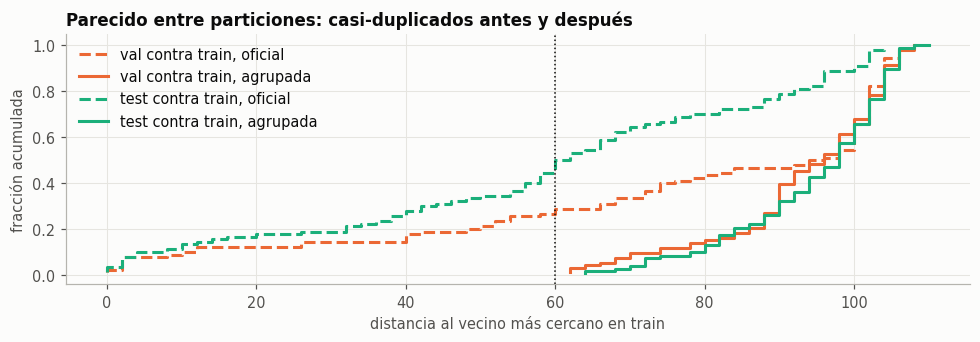

In [6]:
sens = []
for t in (30, 40, 50, 60, 70):
    g = E.grupos_independencia(df, D, t)
    b = np.bincount(g)
    sens.append({'umbral': t, 'grupos': len(b), 'grupo_mayor': b.max(), 'pct_en_top3': 100 * np.sort(b)[-3:].sum() / len(df)})
display(pd.DataFrame(sens).round(1))

df['grupo'] = E.grupos_independencia(df, D, UMBRAL_PHASH)
df['split'] = E.particion_agrupada(df, df.grupo.to_numpy())
print('Grupos de independencia:', df.grupo.nunique(), '| en más de una partición:', (df.groupby('grupo').split.nunique() > 1).sum())
resumen = pd.crosstab(df.familia, df.split)[['train', 'val', 'test']]
resumen.loc['total'] = resumen.sum()
display(resumen.assign(pct_train=lambda d: (100 * d.train / d.sum(axis=1)).round(1)))
print((df.split.value_counts(normalize=True).loc[['train', 'val', 'test']] * 100).round(1).to_dict())

fig, ax = plt.subplots(figsize=(9, 3.2))
for (a, b), c in zip([('val', 'train'), ('test', 'train')], ('val', 'test')):
    for col, est, nombre in [('split_oficial', '--', 'oficial'), ('split', '-', 'agrupada')]:
        x = np.sort(D[np.ix_(df[col] == a, df[col] == b)].min(1))
        ax.step(x, np.arange(1, len(x) + 1) / len(x), est, color=COLOR[c], lw=2, label=f'{a} contra train, {nombre}')
ax.axvline(UMBRAL_PHASH, color=TINTA, lw=1, ls=':')
ax.set(title='Parecido entre particiones: casi-duplicados antes y después', xlabel='distancia al vecino más cercano en train', ylabel='fracción acumulada')
ax.legend(); plt.tight_layout(); plt.show()

In [7]:
d = df.merge(mm, on='archivo').merge(mi, on='archivo')
ORDEN = ['train', 'val', 'test']
cons = d.groupby('split').agg(imagenes=('archivo', 'size'), grupos=('grupo', 'nunique'), instancias=('n_comp', 'sum'),
    inst_por_imagen=('n_comp', 'mean'), fg_media_pct=('frac_fg', lambda s: s.mean() * 100), fg_mediana_pct=('frac_fg', lambda s: s.median() * 100),
    verde=('frac_verde', 'mean'), nitidez_med=('nitidez', 'median')).loc[ORDEN].round(4)
display(cons)

def permuta_grupos(col, a, b, n=5000):
    """Prueba de permutación de la diferencia de medias moviendo grupos completos."""
    sub = d[d.split.isin([a, b])]
    por = sub.groupby('grupo').agg(s=(col, 'sum'), n=(col, 'size'), sp=('split', 'first'))
    obs = por[por.sp == a].s.sum() / por[por.sp == a].n.sum() - por[por.sp == b].s.sum() / por[por.sp == b].n.sum()
    rng = np.random.default_rng(SEED); na = (por.sp == a).sum(); nulas = []
    s, nn = por.s.to_numpy(), por.n.to_numpy()
    for _ in range(n):
        o = rng.permutation(len(por)); A, B = o[:na], o[na:]
        nulas.append(s[A].sum() / nn[A].sum() - s[B].sum() / nn[B].sum())
    return obs, (np.sum(np.abs(nulas) >= abs(obs)) + 1) / (n + 1)

d['log_fg'] = np.log10(d.frac_fg)
filas = []
for col in ('log_fg', 'n_comp'):
    for a in ('val', 'test'):
        obs, p = permuta_grupos(col, a, 'train')
        filas.append({'variable': col, 'contraste': f'{a} - train', 'diferencia': obs, 'p_permutacion': p})
display(pd.DataFrame(filas).round(4))

,imagenes,grupos,instancias,inst_por_imagen,fg_media_pct,fg_mediana_pct,verde,nitidez_med
split,,,,,,,,
train,744,146,3532,4.7473,0.0921,0.0642,0.2845,297.1077
val,93,26,479,5.1505,0.1117,0.0696,0.2652,221.5302
test,108,14,391,3.6204,0.0713,0.0480,0.3276,253.7454


,variable,contraste,diferencia,p_permutacion
0,log_fg,val - train,0.0983,0.3651
1,log_fg,test - train,-0.1436,0.3581
2,n_comp,val - train,0.4032,0.5735
3,n_comp,test - train,-1.1269,0.2212


In [8]:
col_man = ['archivo', 'split_oficial', 'split', 'grupo', 'familia', 'sha256_img', 'sha256_mask']
df[col_man].sort_values('archivo').to_csv(E.RESULTS / 'particion.csv', index=False)
huellas = {k: E.huella_particion(df.archivo[df.split == k], df.sha256_img[df.split == k]) for k in ORDEN}
print(json.dumps(huellas, indent=1))
train = df[df.split == 'train'].reset_index(drop=True)
dtr = d[d.split == 'train'].reset_index(drop=True)
itr = ins[ins.archivo.isin(train.archivo)].reset_index(drop=True)
print(f'A partir de aquí, solo train: {len(train)} imágenes y {len(itr)} componentes.')

{
 "train": "efb6e322326e5d935919045586c4169155cb2fb0f7d44294f72eb7efa2b984c4",
 "val": "8252f051f632fa44a1be3f1e39146d0b35422232b986043003caa73b3d2b9166",
 "test": "af1fed4e311dfab3fe2762961b6d6b5bbd6c36184ff179af77247a76e16e80fa"
}
A partir de aquí, solo train: 744 imágenes y 3532 componentes.


**Lectura.** La partición resultante es de 744 / 93 / 108 imágenes (78,7 / 9,8 / 11,4 %), con 186 grupos y ninguno compartido. La distancia mínima entre particiones supera el umbral de 60, y la curva muestra que la cola de casi-duplicados desaparece.

El umbral no es delicado: de 30 a 60 el grupo mayor sigue en 48 imágenes y el grafo no colapsa. A 70 empieza a crecer (64).

La distribución del objetivo es consistente. La prueba de permutación que mueve grupos completos no detecta diferencias entre train y val/test, ni en fracción de tornillo (p = 0,37 y 0,36) ni en tornillos por imagen (p = 0,57 y 0,22). No detectar diferencias no demuestra igualdad, y esta prueba tiene poca potencia con pocos grupos.

**El conjunto de prueba queda congelado** por los hashes de arriba y por `results/eda/particion.csv`. Desde aquí, todo análisis de píxeles usa solo train. Antes de este punto, val y test se tocaron únicamente por nombres, hashes, pHash y resúmenes agregados.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Usar `particion.csv` como partición principal. Evaluar la partición oficial solo como análisis secundario, para comparar con la literatura. Ajustar todo solo en train. |
| **Arquitectura** | Mismo pipeline, partición y semillas para los tres modelos base. Selección de hiperparámetros con validación fija o por grupos, nunca aleatoria por imagen. |
| **Riesgos** | Test tiene solo **14 grupos** y val 26, así que hay menos unidades independientes de lo que sugieren sus 108 y 93 imágenes. El bootstrap debería remuestrear grupos además de imágenes. `numerico` y `screen` quedan solo en train. `screws` conserva probablemente los mismos microondas en distintas particiones, en otras posiciones: es una fuga residual que se declara y no se elimina. |


## 5. Inspección visual de imágenes y máscaras (train)

Una imagen por familia con el contorno de la máscara en rojo, recortada alrededor de los tornillos a resolución nativa.


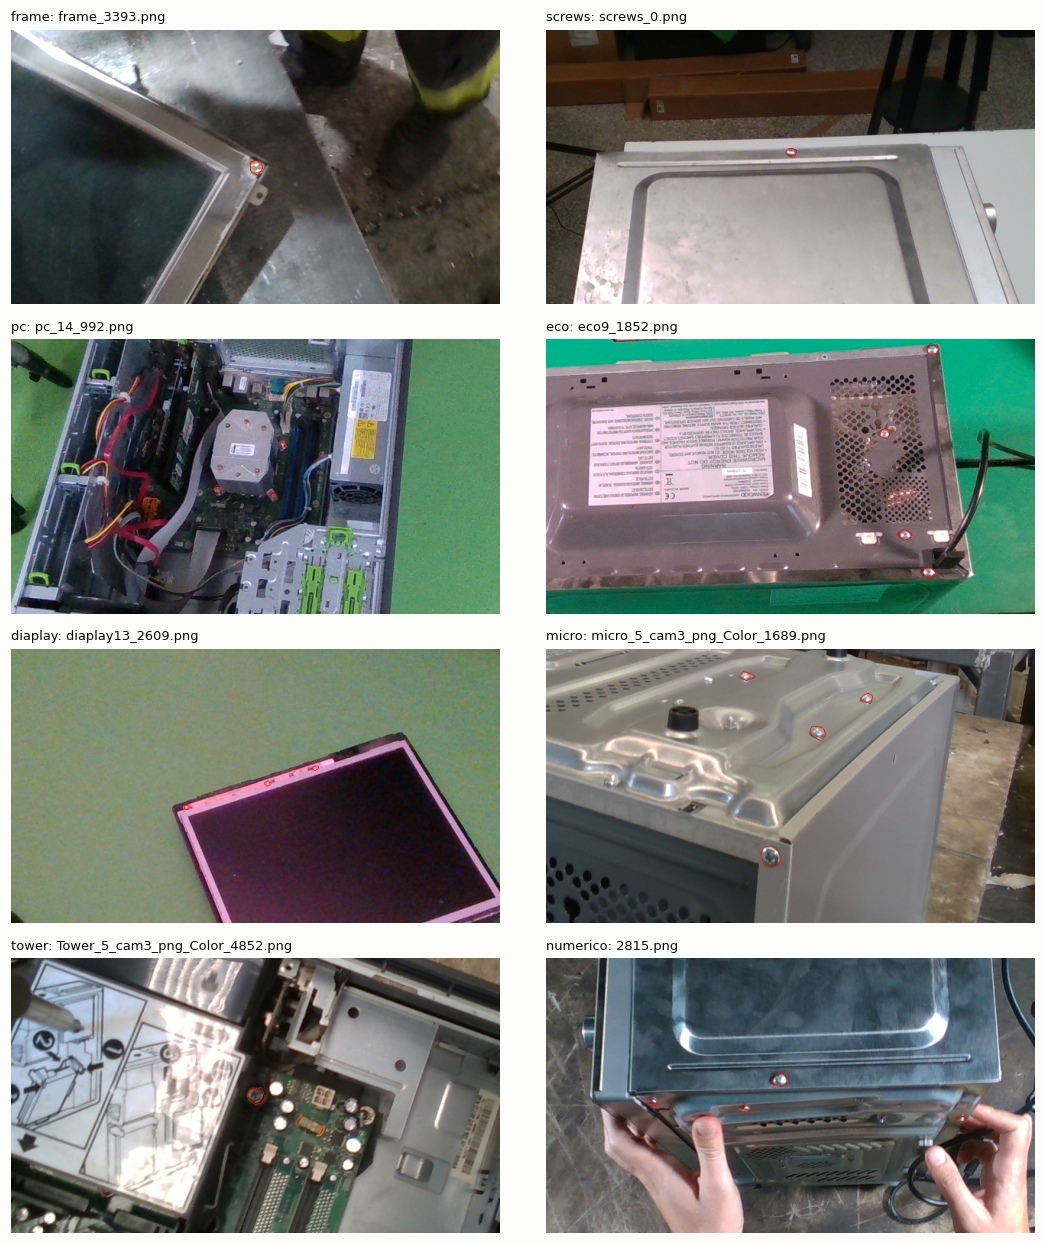

In [9]:
rng = np.random.default_rng(SEED)
fams = [f for f in ['frame', 'screws', 'pc', 'eco', 'diaplay', 'micro', 'tower', 'numerico']]
fig, axs = plt.subplots(4, 2, figsize=(10, 11.4))
for ax, f in zip(axs.ravel(), fams):
    x = train[train.familia == f].sample(1, random_state=SEED).iloc[0]
    im = np.array(Image.open(x.ruta_img).convert('RGB')); m = np.asarray(Image.open(x.ruta_mask)) > 0
    im[find_boundaries(m, mode='outer')] = [255, 0, 0]
    ys, xs = np.nonzero(m); h, w = 360, 640
    y0 = int(np.clip(ys.mean() - h / 2, 0, 720 - h)); x0 = int(np.clip(xs.mean() - w / 2, 0, 1280 - w))
    ax.imshow(im[y0:y0 + h, x0:x0 + w]); ax.set_title(f'{f}: {x.archivo}', fontsize=8.5, fontweight='normal'); ax.axis('off')
plt.tight_layout(); plt.show()

**Lectura.** Las máscaras están bien alineadas y cubren el tornillo. Son polígonos con pocos vértices, así que el contorno es grueso y suele incluir algo de fondo. Se ven dominios muy distintos: mesa verde, mesa blanca, suelo de planta, y cámara en mano con guantes y manos. Algunos tornillos aparecen casi en primer plano y otros son puntos de unos pocos píxeles.

En una revisión previa de 8 imágenes aparecieron candidatos sin anotar en bordes de carcasa, que podrían ser tornillos o remaches. Con 8 imágenes **no se puede estimar una tasa de omisión**, y hacerlo requiere una auditoría manual más amplia.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Conservar las anotaciones tal como están. Reservar una auditoría manual de omisiones como tarea aparte. |
| **Arquitectura** | La red debe combinar detalle fino y contexto del equipo: un tornillo pequeño se distingue de un remache o un agujero por su entorno. |
| **Riesgos** | Tornillos reales sin anotar contarían como falsos positivos y penalizarían injustamente la precisión. No hay acuerdo entre anotadores disponible. |


## 6. Distribución de clases a nivel de píxel (train)

El objetivo es binario, así que el desbalance se mide en píxeles.


Primer plano: 0.0921 % de los píxeles | razón fondo:tornillo = 1,084:1 | entropía = 0.0106 bits (máximo 1)
Por imagen: mediana 0.0642 %, máximo 1.284 %
Asimetría de la fracción: 4.78; curtosis: 33.78
Predictor "todo fondo": exactitud de píxel 99.908 %, Dice 0, mIoU 0.500
Peso de tornillo en entropía ponderada: {'inversa': 1084.3, 'raiz_inversa': 32.9}


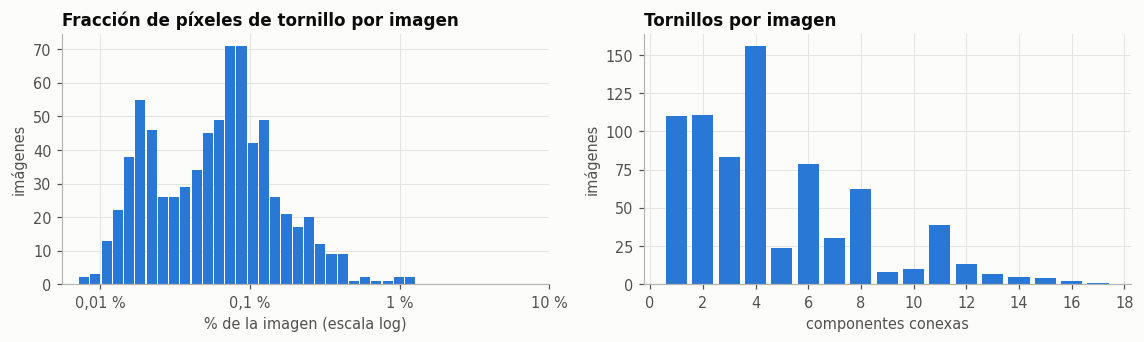

In [10]:
px_fg, px_tot = dtr.px_fg.sum(), len(dtr) * E.H * E.W
p1 = px_fg / px_tot
H_bits = -(p1 * np.log2(p1) + (1 - p1) * np.log2(1 - p1))
print(f'Primer plano: {100 * p1:.4f} % de los píxeles | razón fondo:tornillo = {(1 - p1) / p1:,.0f}:1 | entropía = {H_bits:.4f} bits (máximo 1)')
print(f'Por imagen: mediana {100 * dtr.frac_fg.median():.4f} %, máximo {100 * dtr.frac_fg.max():.3f} %')
print(f'Asimetría de la fracción: {stats.skew(dtr.frac_fg):.2f}; curtosis: {stats.kurtosis(dtr.frac_fg):.2f}')
print(f'Predictor "todo fondo": exactitud de píxel {100 * (1 - p1):.3f} %, Dice 0, mIoU {(1 - p1) / 2:.3f}')
pesos = {'inversa': (1 - p1) / p1, 'raiz_inversa': np.sqrt((1 - p1) / p1)}
print('Peso de tornillo en entropía ponderada:', {k: round(v, 1) for k, v in pesos.items()})

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.2))
axs[0].hist(np.log10(dtr.frac_fg * 100), bins=30, color=COLOR['train'], rwidth=.9)
axs[0].set_xticks([-2, -1, 0, 1], ['0,01 %', '0,1 %', '1 %', '10 %'])
axs[0].set(title='Fracción de píxeles de tornillo por imagen', xlabel='% de la imagen (escala log)', ylabel='imágenes')
v = dtr.n_comp.value_counts().sort_index()
axs[1].bar(v.index, v.values, color=COLOR['train'], width=.8)
axs[1].xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
axs[1].set(title='Tornillos por imagen', xlabel='componentes conexas', ylabel='imágenes')
plt.tight_layout(); plt.show()

**Lectura.** El tornillo ocupa el 0,092 % de los píxeles: razón 1.084:1 y entropía de 0,011 bits sobre un máximo de 1. La distribución por imagen está muy sesgada (asimetría 4,78). Un modelo que prediga todo fondo logra 99,908 % de exactitud de píxel y mIoU 0,50 con Dice 0, sin encontrar un solo tornillo. Esto descarta la exactitud de píxel y hace engañoso el mIoU como métrica principal.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Muestrear parches centrados en tornillos, con una proporción controlada de parches de fondo. |
| **Arquitectura** | Pérdida Dice combinada con BCE o focal. Entropía cruzada sola tenderá a colapsar en todo fondo. Una ponderación inversa pura (peso 1.084) es inestable; si se pondera, partir de la raíz (≈ 33). Inicializar el sesgo de la capa final con la prevalencia. |
| **Riesgos** | Elegir modelo por exactitud o mIoU. Reportar Dice agregado por píxel, que dejaría dominar a los tornillos grandes: por eso la primaria se promedia por imagen. |


## 7. Tamaño, número y forma de los tornillos (train)

Cada componente conexa de la máscara equivale a un tornillo. Se excluyen de esta tabla las componentes de menos de 5 px, que son artefactos (sección 10).


,count,mean,std,min,1%,5%,50%,95%,99%,max
area,3530.0,178.973,352.483,22.000,30.290,43.000,104.000,544.650,1187.130,11832.000
diametro,3530.0,13.394,6.964,5.293,6.210,7.399,11.507,26.334,38.878,122.739
pct_imagen,3530.0,0.019,0.038,0.002,0.003,0.005,0.011,0.059,0.129,1.284
aspecto,3530.0,1.181,0.209,1.000,1.000,1.000,1.125,1.533,1.981,4.333
solidez,3530.0,0.928,0.025,0.752,0.855,0.885,0.930,0.964,0.976,1.000
excentricidad,3530.0,0.562,0.150,0.098,0.216,0.310,0.566,0.803,0.895,0.978


Asimetría del área: 17.0; curtosis: 441.2
Tocan el borde de la imagen: 0.00 %
Categorías COCO por tamaño: pequeñas (<32²) 98.7 %, medianas 1.2 %, grandes 0.0 %
Área por familia, Kruskal-Wallis: H=1619, p=0.00e+00


,count,50%,max
familia,,,
diaplay,527,62,152
pc,368,80,196
screws,1252,92,11832
eco,427,111,257
numerico,118,136,351
tower,77,245,926
frame,456,277,2051
micro,304,326,1470
screen,1,329,329


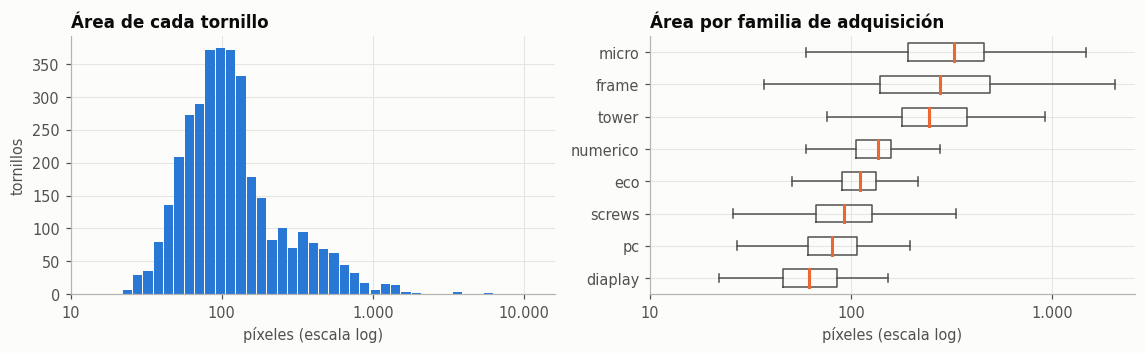

In [11]:
itr['diametro'] = np.sqrt(4 * itr.area / np.pi)
itr['pct_imagen'] = 100 * itr.area / (E.H * E.W)
itr['aspecto'] = itr[['alto', 'ancho']].max(axis=1) / itr[['alto', 'ancho']].min(axis=1)
limpio = itr[itr.area >= 5]
display(limpio[['area', 'diametro', 'pct_imagen', 'aspecto', 'solidez', 'excentricidad']].describe(percentiles=[.01, .05, .5, .95, .99]).T.round(3))
print(f'Asimetría del área: {stats.skew(limpio.area):.1f}; curtosis: {stats.kurtosis(limpio.area):.1f}')
print(f'Tocan el borde de la imagen: {100 * limpio.toca_borde.mean():.2f} %')
print(f'Categorías COCO por tamaño: pequeñas (<32²) {100 * (limpio.area < 32**2).mean():.1f} %, medianas {100 * ((limpio.area >= 32**2) & (limpio.area < 96**2)).mean():.1f} %, grandes {100 * (limpio.area >= 96**2).mean():.1f} %')

por_f = limpio.merge(train[['archivo', 'familia']], on='archivo')
kw = stats.kruskal(*[g.area.values for _, g in por_f.groupby('familia') if len(g) >= 20])
print(f'Área por familia, Kruskal-Wallis: H={kw.statistic:.0f}, p={kw.pvalue:.2e}')
tam = por_f.groupby('familia').area.describe(percentiles=[.5])[['count', '50%', 'max']].astype(int).sort_values('50%')
display(tam)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
axs[0].hist(np.log10(limpio.area), bins=40, color=COLOR['train'], rwidth=.9)
axs[0].set_xticks([1, 2, 3, 4], ['10', '100', '1.000', '10.000'])
axs[0].set(title='Área de cada tornillo', xlabel='píxeles (escala log)', ylabel='tornillos')
orden = tam.index[tam['count'] >= 20]
axs[1].boxplot([np.log10(por_f[por_f.familia == f].area) for f in orden], vert=False, labels=orden, widths=.55, showfliers=False,
               medianprops=dict(color=COLOR['val'], lw=2), boxprops=dict(color=GRIS), whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS))
axs[1].set_xticks([1, 2, 3], ['10', '100', '1.000'])
axs[1].set(title='Área por familia de adquisición', xlabel='píxeles (escala log)')
plt.tight_layout(); plt.show()

**Lectura.** El tornillo mediano mide 104 px² (11,5 px de diámetro) y el 5 % más pequeño baja de 7,4 px. El 98,7 % cae en la categoría "pequeño" de COCO. La forma es muy regular (solidez 0,93, razón de aspecto 1,13): son manchas compactas casi circulares. Ninguna toca el borde de la imagen.

Hay un gran **cambio de escala por familia** (Kruskal-Wallis H = 1.619): la mediana va de 62 px² en `diaplay` a 326 px² en `micro`, con primeros planos de hasta 11.832 px² en `screws` (asimetría 17). Hay 4,7 tornillos por imagen, con un máximo de 17 en todo el dataset.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Augmentation de escala moderada, porque la variación es real: un factor de 2,3 en diámetro entre las familias extremas. Interpolar máscaras con vecino más cercano. |
| **Arquitectura** | Con diámetro de 11,5 px, una celda de stride 16 ya es mayor que el tornillo. Hacen falta conexiones de salto o una salida de stride fino: U-Net reducida o FCN con saltos. Una FCN-32 sin saltos no puede delinear estos objetos. |
| **Riesgos** | Un Dice global esconde el fallo en tornillos pequeños. Conviene reportar por rango de tamaño y por familia. Los pocos primeros planos muy grandes pueden dominar el Dice por píxel. |


## 8. Resolución de entrada y recorte en parches (train)

Dos preguntas: cuánta señal se pierde al reducir la imagen, y qué tamaño de parche conviene si no se reduce.

El **Dice techo** es el de una máscara perfecta reducida a esa resolución y devuelta a 1280×720. Ningún modelo que prediga a esa resolución y se evalúe a la original puede superarlo en promedio, por muy bueno que sea.


,escala,dice_techo,dice_p10,area_efectiva_mediana,pct_inst_>=16px,megapixeles
0,1280x720,1.000,1.000,104.000,100.000,0.922
1,960x540,0.956,0.933,58.500,99.405,0.518
2,512x512,0.920,0.881,29.582,85.949,0.262
3,640x360,0.928,0.896,26.000,80.822,0.230
4,512x288,0.889,0.840,16.640,52.975,0.147
5,256x256,0.843,0.771,7.396,17.847,0.066
6,320x180,0.845,0.769,6.500,15.892,0.058


,parche,parches,pct_vacios,pct_fg_no_vacios,pct_inst_cortadas
0,256,11160,77.052,0.407,9.711
1,384,5952,59.711,0.233,5.776
2,512,4464,36.604,0.174,4.587


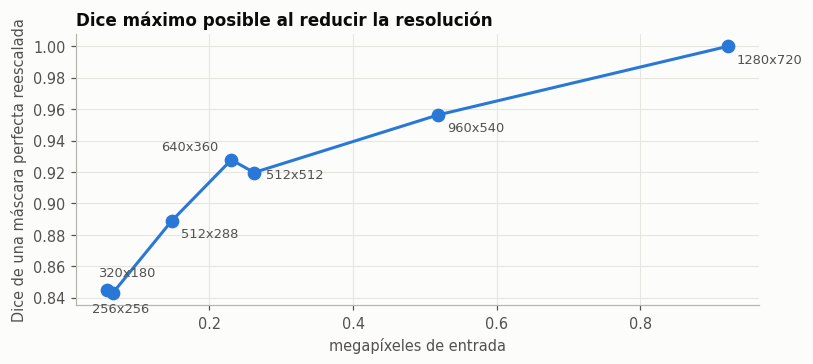

In [12]:
rutas_tr = train.ruta_mask.tolist()
res = E.efecto_resolucion(rutas_tr); res.to_csv(E.RESULTS / 'efecto_resolucion.csv', index=False)
tabla_res = res.groupby('escala').agg(dice_techo=('dice_techo', 'mean'), dice_p10=('dice_techo', lambda s: s.quantile(.1))).reset_index()
tabla_res['area_efectiva_mediana'] = [limpio.area.median() * (E.ESCALAS[e][0] / E.W) * (E.ESCALAS[e][1] / E.H) for e in tabla_res.escala]
tabla_res['pct_inst_>=16px'] = [100 * ((limpio.area * (E.ESCALAS[e][0] / E.W) * (E.ESCALAS[e][1] / E.H)) >= 16).mean() for e in tabla_res.escala]
tabla_res['megapixeles'] = [E.ESCALAS[e][0] * E.ESCALAS[e][1] / 1e6 for e in tabla_res.escala]
tabla_res = tabla_res.sort_values('megapixeles', ascending=False).reset_index(drop=True)
display(tabla_res.round(3))
parches = E.analisis_parches(rutas_tr); parches.to_csv(E.RESULTS / 'parches.csv', index=False)
display(parches.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(tabla_res.megapixeles, tabla_res.dice_techo, '-o', color=COLOR['train'], lw=2, ms=8)
desvio = {'640x360': (-46, 6), '512x512': (8, -4), '320x180': (-6, 9), '256x256': (-14, -13)}
for _, f in tabla_res.iterrows():
    ax.annotate(f.escala, (f.megapixeles, f.dice_techo), textcoords='offset points', xytext=desvio.get(f.escala, (6, -11)), color=GRIS, fontsize=8.5)
ax.set(title='Dice máximo posible al reducir la resolución', xlabel='megapíxeles de entrada', ylabel='Dice de una máscara perfecta reescalada')
plt.tight_layout(); plt.show()

**Lectura.** Reducir tiene un coste directo. A 256×256 el techo cae a 0,84 y solo el 18 % de los tornillos conserva 16 px o más de área (unos 4×4 px). A 512×512 el techo es 0,92, pero esa entrada deforma la imagen. La única opción sin pérdida es la resolución nativa, que a una imagen completa es costosa en memoria.

Los parches resuelven esa tensión. Con 512×512 sin solape, el 36,6 % sale vacío y se corta el 4,6 % de los tornillos. Con 256×256, el 77 % sale vacío, y el contexto del equipo se reduce mucho.

| Conclusión | |
|---|---|
| **Preprocesamiento** | **Parches de 512×512 a resolución nativa** para entrenar. Inferencia por ventana deslizante con solape de al menos 40 px, por encima del percentil 99 del diámetro (38,9 px), para que un tornillo típico quede entero en alguna ventana. Evaluar siempre a 1280×720. |
| **Arquitectura** | Codificador-decodificador de 3 o 4 niveles, con pocos filtros. Tamaño de lote por verificar en la GPU de 6 GB. |
| **Riesgos** | Comparar modelos a resoluciones distintas invalida la comparación. Las costuras entre ventanas pueden crear artefactos. Los valores del techo son cotas por resolución, no estimaciones de rendimiento. |


## 9. Estadísticos de intensidad (train)

Media y desviación estándar se calculan solo con train. La tabla por familia busca diferencias de adquisición, y el contraste tornillo-aro mide qué tan visible es el objeto frente a sus 4 px vecinos.


{'media_rgb_0_1': [0.38552, 0.46256, 0.41176], 'std_rgb_0_1': [0.22329, 0.21101, 0.20605], 'n_imagenes': 744}


,n,brillo,contraste,verde,nitidez,sat_alta_pct,sat_baja_pct
familia,,,,,,,
screen,1,116.66,43.99,0.00,83.84,0.01,0.01
micro,75,110.27,50.49,0.01,135.28,1.57,0.20
numerico,30,104.93,53.58,0.02,319.38,1.89,0.22
tower,33,114.02,48.59,0.03,178.20,0.80,0.11
frame,131,102.34,55.82,0.04,213.67,2.10,0.75
screws,172,106.39,57.64,0.05,211.46,0.25,0.53
pc,123,104.85,42.75,0.62,547.11,0.76,0.03
diaplay,85,113.67,37.54,0.65,439.63,0.02,0.01
eco,94,107.56,42.02,0.69,472.69,0.73,0.21


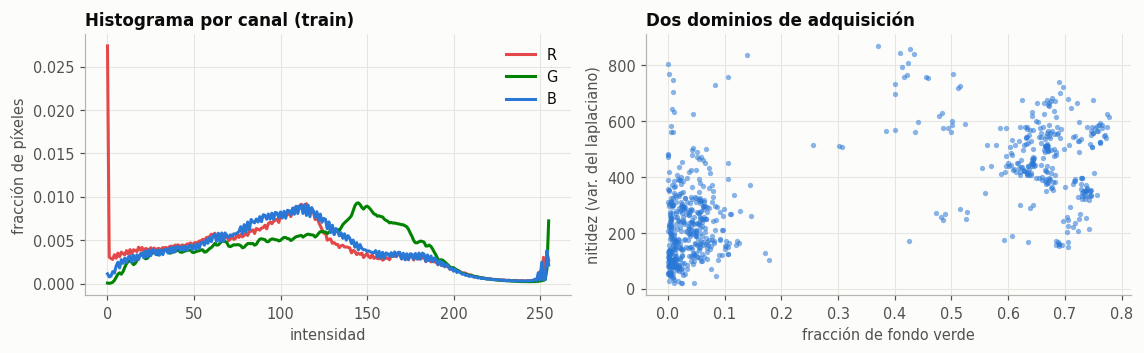

Imágenes con >5 % de píxeles saturados: 15 | con >5 % casi negros: 4
Nitidez mínima 20, percentil 5 79
Tornillo vs. aro vecino: |diferencia| mediana 19.6 niveles; |z| mediano 1.00; más claros que el aro: 57.6 %; |z|<0,5: 28.9 %


In [13]:
cache = E.RESULTS / 'hist_train.npy'
if cache.exists() and len(np.load(E.RESULTS / 'hist_train_n.npy', allow_pickle=True)) == len(train):
    hist = np.load(cache)
else:
    hist = E.histogramas_rgb(train.ruta_img)
    np.save(cache, hist); np.save(E.RESULTS / 'hist_train_n.npy', train.archivo.values, allow_pickle=True)
v = np.arange(256)
media = (hist * v).sum(1) / hist.sum(1)
std = np.sqrt((hist * (v - media[:, None]) ** 2).sum(1) / hist.sum(1))
norma = {'media_rgb_0_1': (media / 255).round(5).tolist(), 'std_rgb_0_1': (std / 255).round(5).tolist(), 'n_imagenes': len(train)}
(E.RESULTS / 'normalizacion_train.json').write_text(json.dumps(norma, indent=1), encoding='utf8')
print(norma)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
for c, (n, col) in enumerate(zip(('R', 'G', 'B'), ('#e34948', '#008300', '#2a78d6'))):
    axs[0].plot(v, hist[c] / hist[c].sum(), color=col, lw=2, label=n)
axs[0].set(title='Histograma por canal (train)', xlabel='intensidad', ylabel='fracción de píxeles'); axs[0].legend()
t = dtr.groupby('familia').agg(n=('archivo', 'size'), brillo=('gris_media', 'mean'), contraste=('contraste', 'mean'), verde=('frac_verde', 'mean'), nitidez=('nitidez', 'median'), sat_alta_pct=('sat_alta', lambda s: 100 * s.mean()), sat_baja_pct=('sat_baja', lambda s: 100 * s.mean()))
display(t.sort_values('verde').round(2))
axs[1].scatter(dtr.frac_verde, dtr.nitidez, s=12, color=COLOR['train'], alpha=.55, linewidths=0)
axs[1].set(title='Dos dominios de adquisición', xlabel='fracción de fondo verde', ylabel='nitidez (var. del laplaciano)')
plt.tight_layout(); plt.show()
print('Imágenes con >5 % de píxeles saturados:', (dtr.sat_alta > .05).sum(), '| con >5 % casi negros:', (dtr.sat_baja > .05).sum())
print(f'Nitidez mínima {dtr.nitidez.min():.0f}, percentil 5 {dtr.nitidez.quantile(.05):.0f}')

c = limpio.dropna(subset=['media_aro'])
delta = c.media_dentro - c.media_aro
z = delta / c.std_aro.clip(lower=1)
print(f'Tornillo vs. aro vecino: |diferencia| mediana {delta.abs().median():.1f} niveles; |z| mediano {z.abs().median():.2f}; más claros que el aro: {100 * (delta > 0).mean():.1f} %; |z|<0,5: {100 * (z.abs() < .5).mean():.1f} %')

**Lectura.** Los estadísticos de train son media RGB (0,386; 0,463; 0,412) y desviación (0,223; 0,211; 0,206), guardados en `results/eda/normalizacion_train.json`. El pico del canal R en 0 y la meseta de G cerca de 150 vienen de la mesa verde.

Hay **dos dominios claros**: con mesa verde (`pc`, `eco`, `diaplay`, 60-70 % del encuadre, nitidez alta) y sin ella (nitidez más baja, cámara en mano y planta). La saturación es poco frecuente: 15 imágenes con más del 5 % de píxeles saturados y 4 con más del 5 % casi negros.

El tornillo no se distingue por brillo: el 57,6 % es más claro que su entorno, y el 28,9 % queda a menos de medio desvío estándar del aro vecino. Un umbral de intensidad no sirve y la red tiene que usar forma y textura.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Normalizar con los estadísticos de train. Augmentation fotométrica de brillo, contraste y tono, para no depender del fondo verde. No eliminar imágenes por saturación. |
| **Arquitectura** | Mantener resolución alta en las primeras capas, donde se captura la textura. La normalización por lotes debe vigilarse con lotes pequeños y dos dominios tan distintos. |
| **Riesgos** | Sobreajuste al dominio: un modelo puede ir bien en mesa verde y mal en planta. Usar estadísticos globales con val o test sería fuga. |


## 10. Calidad de la anotación (train)

Hay dos versiones de cada anotación, los polígonos COCO y el PNG semántico. Antes de usarlas como medida de ruido hay que comprobar si realmente son independientes. Además, se perturban las máscaras 1 px para medir cuánto castiga Dice un error de borde mínimo.


PNG vs. COCO (train): Dice 0.912, IoU 0.841; píxeles COCO/PNG 1.013
Mismo número de objetos: 99.7 % de las imágenes
Componentes de área < 5 px en todo el dataset: 4; total componentes 4402; total COCO 4398; página oficial 4.414


Dice PNG vs. COCO al mover COCO (dy, dx): {(0, 0): 0.912, (0, 1): 0.927, (1, 0): 0.919, (1, 1): 0.924}


,mean,std,min,50%
desplazada 1 px (x),0.896,0.039,0.784,0.896
desplazada 1 px (x e y),0.850,0.055,0.674,0.847
erosionada 1 px,0.831,0.065,0.624,0.829
dilatada 1 px,0.864,0.044,0.745,0.860


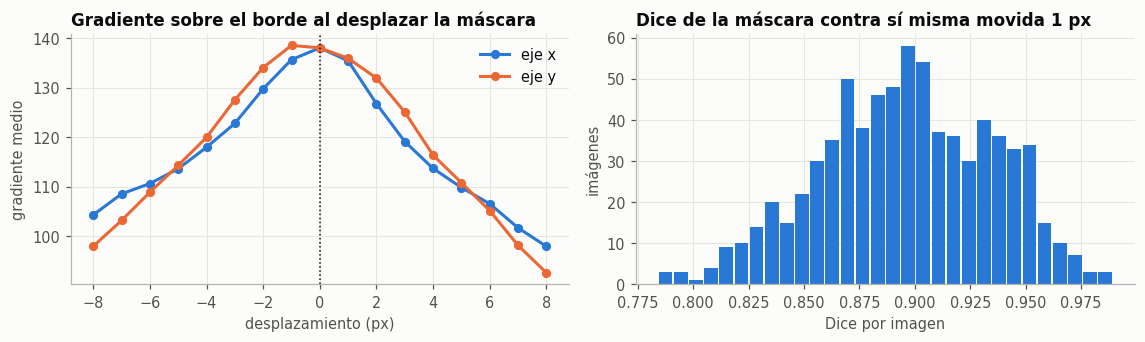

In [14]:
ac = E.acuerdo_coco_png(df)
ac = ac[ac.archivo.isin(train.archivo)]
print(f'PNG vs. COCO (train): Dice {ac.dice.mean():.3f}, IoU {ac.iou.mean():.3f}; píxeles COCO/PNG {(ac.px_coco / ac.px_png).mean():.3f}')
print(f'Mismo número de objetos: {100 * (ac.n_coco == ac.n_comp_png).mean():.1f} % de las imágenes')
print(f'Componentes de área < 5 px en todo el dataset: {(ins.area < 5).sum()}; total componentes {len(ins)}; total COCO {sum(len(v["annotations"]) for v in coco.values())}; página oficial 4.414')

rut = dict(zip(train.archivo, train.ruta_mask))
dices = {(0, 0): [], (0, 1): [], (1, 0): [], (1, 1): []}
for dd in coco.values():
    por = {}
    for a_ in dd['annotations']:
        por.setdefault(a_['image_id'], []).append(a_)
    for im_ in dd['images']:
        if im_['file_name'] in rut:
            m_ = np.asarray(Image.open(rut[im_['file_name']])) > 0
            c_ = E.rasteriza_coco(por[im_['id']])
            for k_ in dices:
                s_ = np.roll(c_, k_, (0, 1))
                dices[k_].append(2 * (m_ & s_).sum() / (m_.sum() + s_.sum()))
print('Dice PNG vs. COCO al mover COCO (dy, dx):', {k: round(float(np.mean(v)), 3) for k, v in dices.items()})

sb = E.sensibilidad_borde(rutas_tr); sb.to_csv(E.RESULTS / 'sensibilidad_borde.csv', index=False)
display(sb.drop(columns='archivo').describe().T[['mean', 'std', 'min', '50%']].round(3))
muestra = train.sample(150, random_state=SEED)
al = E.perfil_alineacion(list(zip(muestra.ruta_img, muestra.ruta_mask))); al.to_csv(E.RESULTS / 'alineacion.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.2))
for eje, col in zip('xy', (COLOR['train'], COLOR['val'])):
    s = al[al.eje == eje]; axs[0].plot(s.d, s.grad, '-o', ms=5, lw=2, color=col, label=f'eje {eje}')
axs[0].axvline(0, color=TINTA, lw=1, ls=':')
axs[0].set(title='Gradiente sobre el borde al desplazar la máscara', xlabel='desplazamiento (px)', ylabel='gradiente medio'); axs[0].legend()
axs[1].hist(sb['desplazada 1 px (x)'], bins=30, color=COLOR['train'], rwidth=.9)
axs[1].set(title='Dice de la máscara contra sí misma movida 1 px', xlabel='Dice por imagen', ylabel='imágenes')
plt.tight_layout(); plt.show()

**Lectura.** PNG y COCO **no son dos anotadores independientes**. El número de objetos coincide en el 99,7 % de las imágenes y la razón de píxeles es 1,013, así que describen la misma anotación. El Dice de 0,912 entre ellos se debe sobre todo a cómo se rasterizan: al desplazar COCO 1 px en x, el Dice sube de 0,912 a 0,927. Por eso **no es una estimación de acuerdo entre anotadores**.

La alineación imagen-máscara es correcta: el gradiente sobre el borde tiene su máximo en desplazamiento 0, en ambos ejes.

Las 4 componentes de más frente a COCO (4.402 contra 4.398) son exactamente los 4 artefactos de 1 px. La diferencia con las 4.414 de la página oficial no se puede explicar con estos archivos.

El dato más útil es la **fragilidad de Dice en objetos tan pequeños**. Mover la máscara correcta 1 px baja el Dice a 0,896, 1 px en ambos ejes a 0,850, y erosionarla 1 px a 0,831. Un modelo que localice perfectamente cada tornillo pero falle 1 px de contorno quedaría cerca de 0,85-0,90.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Eliminar las componentes de menos de 5 px (4 en todo el dataset). Usar el PNG como referencia única, sin mezclarlo con COCO. |
| **Arquitectura** | Conviene añadir una métrica por instancia, porque en este problema importa encontrar el tornillo más que delinear su contorno al píxel. |
| **Riesgos** | Sin anotador humano independiente no hay cota de desempeño humano: los valores anteriores son sensibilidad, no un techo real. Diferencias pequeñas de Dice pueden deberse a contornos y no a detectar mejor. |


## 11. Sesgos y desplazamiento de distribución

Primero, solo con train, se buscan atajos: posición en la imagen y relación entre ambiente y etiqueta. Después se comparan las particiones con un clasificador adversarial y pruebas de dos muestras sobre 12 rasgos simples, usando únicamente resúmenes por imagen.

El clasificador se valida sin romper grupos. Un AUC de 0,5 significa que no distingue train del resto.


Centro de masa: x=0.540, y=0.515; std x=0.174, y=0.226; celdas con tornillos: 83.0 %
Tornillos en el 10 % exterior de la imagen: 9.7 %


,imagenes,fg_mediana_pct,tornillos_por_imagen,nitidez
frac_verde,,,,
sin fondo verde,443,0.0896,4.9932,204.3146
fondo verde,301,0.0328,4.3854,489.4244


Spearman(fondo verde, fracción de tornillo) = -0.429, p=1.1e-34


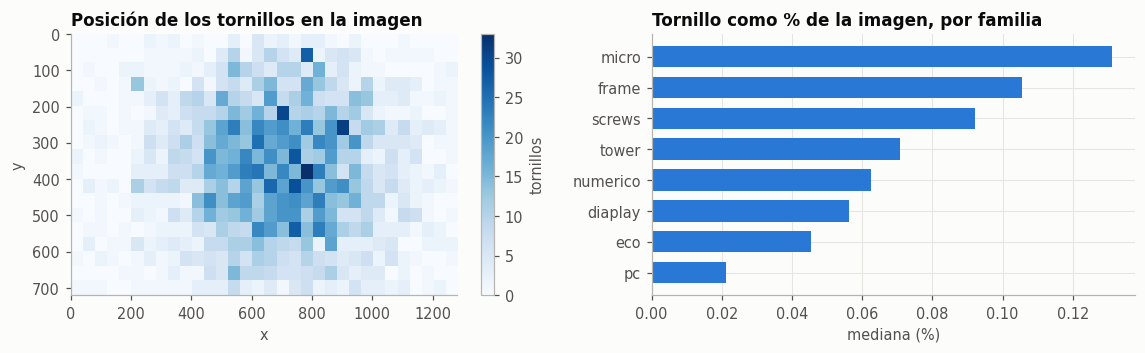

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
hm, _, _ = np.histogram2d(itr.cy, itr.cx, bins=(18, 32), range=[[0, 720], [0, 1280]])
im = axs[0].imshow(hm, cmap='Blues', extent=(0, 1280, 720, 0), aspect='auto'); axs[0].grid(False)
axs[0].set(title='Posición de los tornillos en la imagen', xlabel='x', ylabel='y'); plt.colorbar(im, ax=axs[0], label='tornillos')
marg = (hm > 0).mean() * 100
y = itr.cy / 720; x = itr.cx / 1280
print(f'Centro de masa: x={x.mean():.3f}, y={y.mean():.3f}; std x={x.std():.3f}, y={y.std():.3f}; celdas con tornillos: {marg:.1f} %')
print(f'Tornillos en el 10 % exterior de la imagen: {100 * (((x < .1) | (x > .9) | (y < .1) | (y > .9))).mean():.1f} %')
ambiente = pd.cut(dtr.frac_verde, [-.01, .3, 1], labels=['sin fondo verde', 'fondo verde'])
a = dtr.groupby(ambiente).agg(imagenes=('archivo', 'size'), fg_mediana_pct=('frac_fg', lambda s: 100 * s.median()), tornillos_por_imagen=('n_comp', 'mean'), nitidez=('nitidez', 'median'))
display(a.round(4))
rho = stats.spearmanr(dtr.frac_verde, dtr.frac_fg)
print(f'Spearman(fondo verde, fracción de tornillo) = {rho.correlation:.3f}, p={rho.pvalue:.1e}')
g = dtr[dtr.familia != 'screen'].groupby('familia').frac_fg.median().sort_values() * 100
axs[1].barh(g.index, g.values, color=COLOR['train'], height=.7)
axs[1].set(title='Tornillo como % de la imagen, por familia', xlabel='mediana (%)')
plt.tight_layout(); plt.show()

In [16]:
RASGOS = ['r_media', 'g_media', 'b_media', 'r_std', 'g_std', 'b_std', 'gris_media', 'contraste', 'sat_alta', 'sat_baja', 'nitidez', 'frac_verde']

def auc_adversarial(col, repes=5):
    """Clasificador train contra resto, validado sin romper grupos."""
    X, y, g = d[RASGOS].to_numpy(), (d[col] != 'train').astype(int).to_numpy(), d.grupo.to_numpy()
    aucs = []
    for r in range(repes):
        cv = StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r)
        for tr, te in cv.split(X, y, g):
            rf = RandomForestClassifier(300, min_samples_leaf=3, class_weight='balanced', n_jobs=-1, random_state=SEED + r).fit(X[tr], y[tr])
            aucs.append(roc_auc_score(y[te], rf.predict_proba(X[te])[:, 1]))
    return np.mean(aucs), np.std(aucs)

filas = []
for nombre, col in [('oficial', 'split_oficial'), ('agrupada', 'split')]:
    m_, s_ = auc_adversarial(col)
    filas.append({'particion': nombre, 'auc_adversarial': m_, 'std': s_})
display(pd.DataFrame(filas).round(3))

ks = []
hold = d[d.split != 'train']
for r in RASGOS:
    k = stats.ks_2samp(dtr[r], hold[r]); ks.append({'rasgo': r, 'ks': k.statistic, 'p': k.pvalue})
ks = pd.DataFrame(ks).sort_values('ks', ascending=False)
ks['p_holm'] = (ks.p * np.arange(len(ks), 0, -1)).cummax().clip(upper=1)
display(ks.round(4))

,particion,auc_adversarial,std
0,oficial,0.488,0.050
1,agrupada,0.598,0.128


,rasgo,ks,p,p_holm
10,nitidez,0.2771,0.0000,0.0000
8,sat_alta,0.1960,0.0000,0.0001
4,g_std,0.1766,0.0001,0.0009
2,b_media,0.1653,0.0003,0.0027
7,contraste,0.1631,0.0004,0.0030
9,sat_baja,0.1609,0.0005,0.0033
0,r_media,0.1437,0.0026,0.0154
3,r_std,0.1435,0.0026,0.0154
5,b_std,0.1230,0.0150,0.0600
1,g_media,0.1212,0.0173,0.0600


**Lectura.**

- **Posición.** Hay sesgo central por el encuadre (centro de masa en x = 0,54, y = 0,52), aunque los tornillos cubren el 83 % de las celdas y solo el 9,7 % cae en el 10 % exterior. Los parches eliminan en buena medida la posición absoluta.
- **Atajo por dominio.** El fondo verde está asociado con tornillos más pequeños (ρ de Spearman = -0,43) y con el doble de nitidez. La mediana de fracción de tornillo es 0,033 % con fondo verde y 0,090 % sin él. El fondo no causa el tamaño, pero una red puede aprender esa asociación.
- **Desplazamiento entre particiones.** El AUC adversarial es 0,49 ± 0,05 en la oficial y 0,60 ± 0,13 en la agrupada. El resultado es esperable, porque separar sesiones reales hace que val y test sean algo distintos de train. Ese es justamente el escenario que se quiere evaluar, y el desplazamiento es moderado.
- **Rasgos.** El mayor cambio aparece en nitidez (KS = 0,28) y saturación alta (KS = 0,20). Estos p-valores tratan cada imagen como independiente y están **sobreestimados en significancia**, así que importa el tamaño del KS y no el p.

| Conclusión | |
|---|---|
| **Preprocesamiento** | Volteos y rotaciones consistentes en imagen y máscara, porque un tornillo no tiene orientación preferida. Mantener la augmentation fotométrica de la sección 9. |
| **Arquitectura** | Los tres modelos deben evaluarse también por dominio (fondo verde o no) y por familia, para exponer un atajo si existe. |
| **Riesgos** | Validez externa: no hay dispositivos fuera de estos tres tipos, ni imágenes borrosas o sin tornillos. La variabilidad entre grupos puede ser mayor que la diferencia entre modelos. |


## 12. Declaración a priori para los entregables 2 y 3

Se guarda en `results/eda/declaracion_a_priori.json`, junto con la partición, los hashes y la normalización.


In [17]:
dec = {
    'dataset': 'WEEE Disassembly Screw Dataset (WDSD)', 'n_imagenes': len(df), 'sha256_dataset': E.huella_dataset(df),
    'tipo_problema': 'Segmentación de imágenes (binaria: tornillo / fondo)',
    'metrica_primaria': 'Dice de la clase tornillo, promediado por imagen', 'metricas_secundarias': ['IoU de tornillo', 'mIoU', 'exactitud de píxel', 'recall y precisión por instancia'],
    'delta_practico': 0.02, 'delta_estado': 'provisional: se confirma con el piloto de la sección 4.1',
    'alpha': 0.05, 'unidad_analisis': 'imagen', 'unidad_independencia': 'grupo de independencia (sesión o escena)',
    'particion': {'semilla': SEED, 'umbral_phash': UMBRAL_PHASH, 'tamanos': df.split.value_counts().to_dict(), 'sha256': huellas, 'archivo': 'results/eda/particion.csv'},
    'normalizacion_train': norma,
}
(E.RESULTS / 'declaracion_a_priori.json').write_text(json.dumps(dec, indent=1, ensure_ascii=False), encoding='utf8')
print(json.dumps({k: dec[k] for k in ('metrica_primaria', 'delta_practico', 'unidad_independencia', 'particion')}, indent=1, ensure_ascii=False))

{
 "metrica_primaria": "Dice de la clase tornillo, promediado por imagen",
 "delta_practico": 0.02,
 "unidad_independencia": "grupo de independencia (sesión o escena)",
 "particion": {
  "semilla": 42,
  "umbral_phash": 60,
  "tamanos": {
   "train": 744,
   "test": 108,
   "val": 93
  },
  "sha256": {
   "train": "efb6e322326e5d935919045586c4169155cb2fb0f7d44294f72eb7efa2b984c4",
   "val": "8252f051f632fa44a1be3f1e39146d0b35422232b986043003caa73b3d2b9166",
   "test": "af1fed4e311dfab3fe2762961b6d6b5bbd6c36184ff179af77247a76e16e80fa"
  },
  "archivo": "results/eda/particion.csv"
 }
}


## 13. Veredicto

| Requisito | Resultado | Estado |
|---|---|---|
| Tipo de problema admitido | Segmentación de imágenes (tipo 8) | Cumple |
| Dataset completo y coherente | 945 pares, sin faltantes ni corruptos | Cumple |
| Público y con uso publicado | Página oficial y artículo de ICRCV 2022 | Cumple |
| Licencia | La página no la declara | **Pendiente** |
| Partición sin fuga | 186 grupos, ninguno compartido; la oficial se descarta como principal | Cumple, con fuga residual declarada en `screws` |
| Test congelado | Hashes guardados | Cumple |
| Bloque G del EDA | Secciones 5 a 10 | Cumple |
| Consistencia de anotadores | No evaluable: solo hay una anotación | **Limitación** |

**WDSD es válido y se recomienda seguir con él.** No hace falta buscar otro dataset, salvo que la licencia resulte un impedimento.

### Decisiones heredadas por los modelos base

| Tema | Decisión |
|---|---|
| Entrada | Parches de 512×512 a resolución nativa; evaluación a 1280×720 con ventana deslizante |
| Normalización | Media y desviación de train |
| Pérdida | Dice más BCE o focal |
| Muestreo | Parches centrados en tornillos, más una fracción de fondo |
| Augmentation | Volteos, rotaciones, escala moderada, brillo, contraste y tono |
| Métrica primaria | Dice de tornillo por imagen; no usar exactitud de píxel |
| Reporte | Por familia, por dominio y por tamaño, además de partición oficial como análisis secundario |
| Inferencia | Por imagen, con bootstrap que respete grupos |

### Pendientes antes de modelar

1. Confirmar la licencia con los autores y conseguir el DOI del artículo.
2. Auditar manualmente una muestra de train para estimar tornillos sin anotar.
3. Comprobar en la revisión de literatura si los trabajos sobre WDSD usan la partición oficial. Si es así, sus cifras podrían no ser comparables con este baseline, y eso podría ser un *gap* formulable.
4. Preparar un entorno con GPU: en `ml_venv`, TensorFlow 2.10 no detecta la GPU y PyTorch no está instalado.
